<a href="https://colab.research.google.com/github/jerem-a11y/crypto-market-analysis/blob/main/crypto_pred.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cryptocurrency Classification Using Machine Learning

## Project Overview

This project uses Machine Learning classification algorithms to identify three cryptocurrencies: Bitcoin (BTC), Ethereum (ETH), and Solana (SOL), based on their historical market data.

The project compares different classification algorithms to determine their performance in distinguishing between the three cryptocurrencies.

**Algorithms:**
- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)

In [93]:
url = url = "https://raw.githubusercontent.com/jerem-a11y/crypto-market-analysis/main/data/crypto_data.csv"

In [94]:
crypto_dt = pd.read_csv(url)

In [95]:
crypto_dt.head()

,Date,Coin,Close,Market_Cap,Volume,Daily_Return,Indexed_Price,MA_30,MA_90,Daily_Return_Decimal,Cumulative_Return,Running_Peak,Drawdown
0,2021-01-01 00:00:00+00:00,BTC,29374.152344,1.196418e+15,40730301359,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-02 00:00:00+00:00,BTC,32127.267578,2.180331e+15,67865420765,9.372578,109.372578,NaN,NaN,0.093726,1.093726,1.093726,0.000000
2,2021-01-03 00:00:00+00:00,BTC,32782.023438,2.578806e+15,78665235202,2.038007,111.601598,NaN,NaN,0.020380,1.116016,1.116016,0.000000
3,2021-01-04 00:00:00+00:00,BTC,31971.914062,2.594952e+15,81163475344,-2.471200,108.843699,NaN,NaN,-0.024712,1.088437,1.116016,-0.024712
4,2021-01-05 00:00:00+00:00,BTC,33992.429688,2.296098e+15,67547324782,6.319658,115.722249,NaN,NaN,0.063197,1.157222,1.157222,0.000000


In [96]:
crypto_dt.describe()

,Close,Market_Cap,Volume,Daily_Return,Indexed_Price,MA_30,MA_90,Daily_Return_Decimal,Cumulative_Return,Running_Peak,Drawdown
count,5478.000000,5.478000e+03,5.478000e+03,5475.000000,5478.000000,5391.000000,5211.000000,5475.000000,5475.000000,5475.000000,5475.000000
mean,19019.903853,8.015050e+14,1.977249e+10,0.225334,1960.980874,18983.659941,18814.922443,0.002253,19.620006,44.163562,-0.423006
std,30289.556105,1.778638e+15,2.084958e+10,4.543052,3284.041626,30184.705404,29809.741098,0.045431,32.846523,61.054889,0.266739
min,1.799275,4.738310e+07,2.572255e+07,-42.280904,53.745497,3.226758,9.235864,-0.422809,0.537455,0.976761,-0.962725
25%,157.006351,5.392740e+11,3.400411e+09,-1.948483,204.300000,158.433903,158.834245,-0.019485,2.048317,2.488021,-0.623194
50%,2448.949097,4.107109e+13,1.437155e+10,0.019329,358.132218,2484.078597,2552.700808,0.000193,3.583341,6.588583,-0.420616
75%,29391.824219,6.865844e+14,2.912320e+10,2.127011,1481.518310,28896.303743,28467.223785,0.021270,14.863736,140.565967,-0.197616
max,124752.531250,2.178225e+16,3.509679e+11,35.703035,14215.950187,117506.825000,115759.452778,0.357030,142.159502,142.159502,0.000000


In [97]:
crypto_dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  5478 non-null   object 
 1   Coin                  5478 non-null   object 
 2   Close                 5478 non-null   float64
 3   Market_Cap            5478 non-null   float64
 4   Volume                5478 non-null   int64  
 5   Daily_Return          5475 non-null   float64
 6   Indexed_Price         5478 non-null   float64
 7   MA_30                 5391 non-null   float64
 8   MA_90                 5211 non-null   float64
 9   Daily_Return_Decimal  5475 non-null   float64
 10  Cumulative_Return     5475 non-null   float64
 11  Running_Peak          5475 non-null   float64
 12  Drawdown              5475 non-null   float64
dtypes: float64(10), int64(1), object(2)
memory usage: 556.5+ KB


In [98]:
crypto_dt.isnull().sum()

,0
Date,0
Coin,0
Close,0
Market_Cap,0
Volume,0
Daily_Return,3
Indexed_Price,0
MA_30,87
MA_90,267
Daily_Return_Decimal,3


In [99]:
crypto_dt.Coin

,Coin
0,BTC
1,BTC
2,BTC
3,BTC
4,BTC
...,...
5473,SOL
5474,SOL
5475,SOL
5476,SOL


In [100]:
unique_coins = crypto_dt['Coin'].unique()
print(unique_coins)

['BTC' 'ETH' 'SOL']


In [115]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report

In [102]:
dropped = crypto_dt.drop(['Coin', 'Daily_Return', 'MA_30',
                          'MA_90', 'Daily_Return_Decimal',
                          'Cumulative_Return',	'Running_Peak', 'Drawdown',
                          'Close', 'Date'], axis=1)

In [103]:
dropped

,Market_Cap,Volume,Indexed_Price
0,1.196418e+15,40730301359,100.000000
1,2.180331e+15,67865420765,109.372578
2,2.578806e+15,78665235202,111.601598
3,2.594952e+15,81163475344,108.843699
4,2.296098e+15,67547324782,115.722249
...,...,...,...
5473,2.133170e+11,1711358748,6766.668041
5474,2.508637e+11,2003713687,6796.614740
5475,5.998473e+11,4871847248,6684.017967
5476,3.868763e+11,3096711898,6782.064053


In [119]:
x = dropped.drop('Volume', axis=1)
y = crypto_dt['Coin']

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [124]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [125]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [127]:
y_pred = model.predict(X_test)
y_pred

array(['ETH', 'BTC', 'ETH', ..., 'BTC', 'BTC', 'BTC'],
      shape=(1096,), dtype=object)

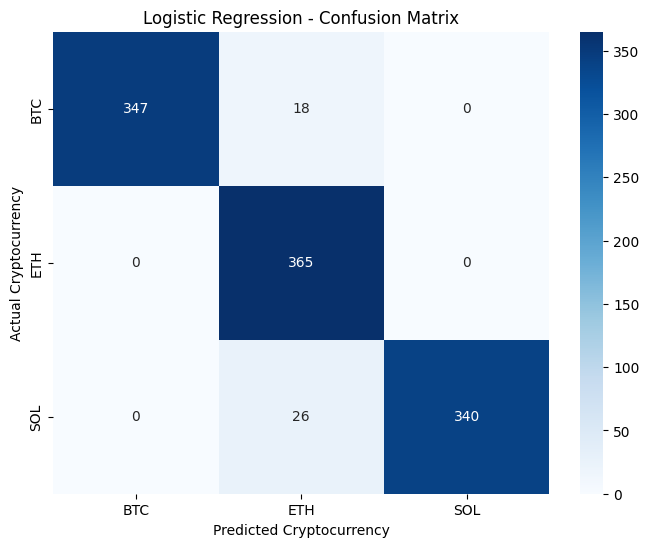

In [131]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)


plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Cryptocurrency')
plt.ylabel('Actual Cryptocurrency')

plt.show()

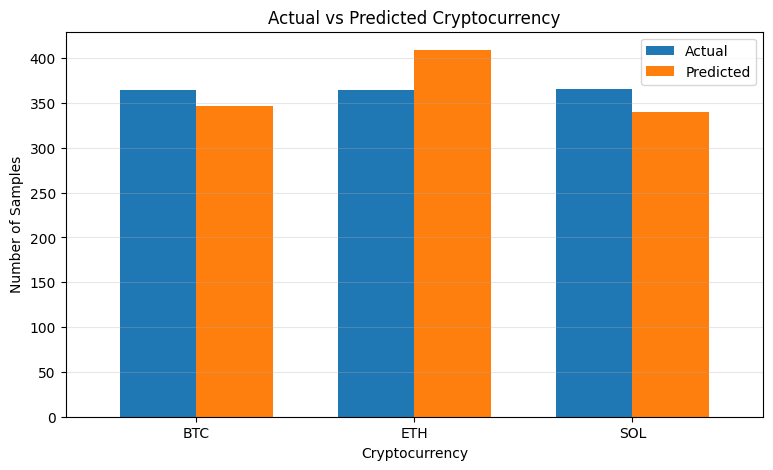

In [133]:
actual = y_test.value_counts().sort_index()
predicted = pd.Series(y_pred).value_counts().sort_index()

comparison = pd.DataFrame({
    'Actual': actual,
    'Predicted': predicted
}).fillna(0)

comparison.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.7
)

plt.title('Actual vs Predicted Cryptocurrency')
plt.xlabel('Cryptocurrency')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

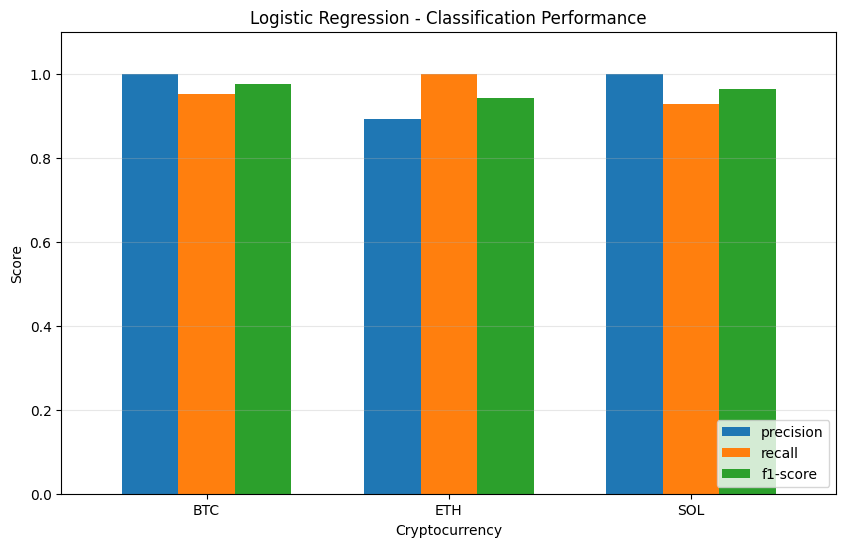

In [134]:
report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

metrics = pd.DataFrame(report).T

metrics = metrics.loc[
    model.classes_,
    ['precision', 'recall', 'f1-score']
]

metrics.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.7
)

plt.title('Logistic Regression - Classification Performance')
plt.xlabel('Cryptocurrency')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [135]:
accuracy = model.score(X_test, y_test)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.99%

Classification Report:
              precision    recall  f1-score   support

         BTC       1.00      0.95      0.97       365
         ETH       0.89      1.00      0.94       365
         SOL       1.00      0.93      0.96       366

    accuracy                           0.96      1096
   macro avg       0.96      0.96      0.96      1096
weighted avg       0.96      0.96      0.96      1096



In [139]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [140]:
# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [141]:
# Train model
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [142]:
# Make predictions
rf_pred = rf_model.predict(X_test)

In [143]:
rf_accuracy = accuracy_score(y_test, rf_pred)

In [144]:
print(f"Random Forest Accuracy: {rf_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

         BTC       1.00      1.00      1.00       365
         ETH       1.00      1.00      1.00       365
         SOL       1.00      1.00      1.00       366

    accuracy                           1.00      1096
   macro avg       1.00      1.00      1.00      1096
weighted avg       1.00      1.00      1.00      1096



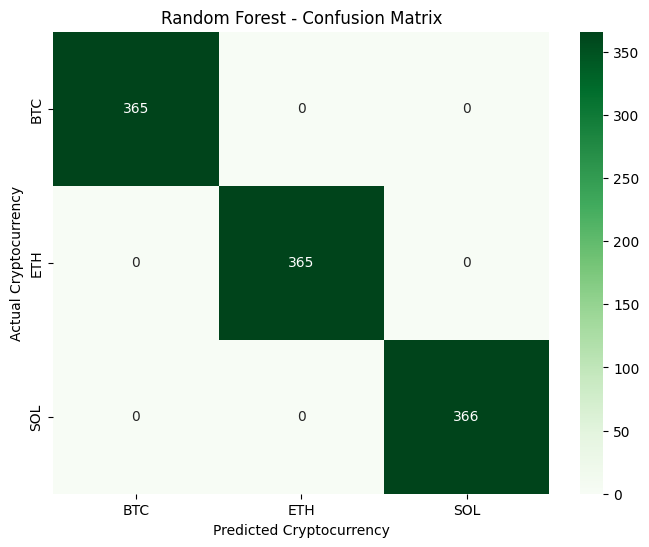

In [145]:
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Cryptocurrency')
plt.ylabel('Actual Cryptocurrency')

plt.show()

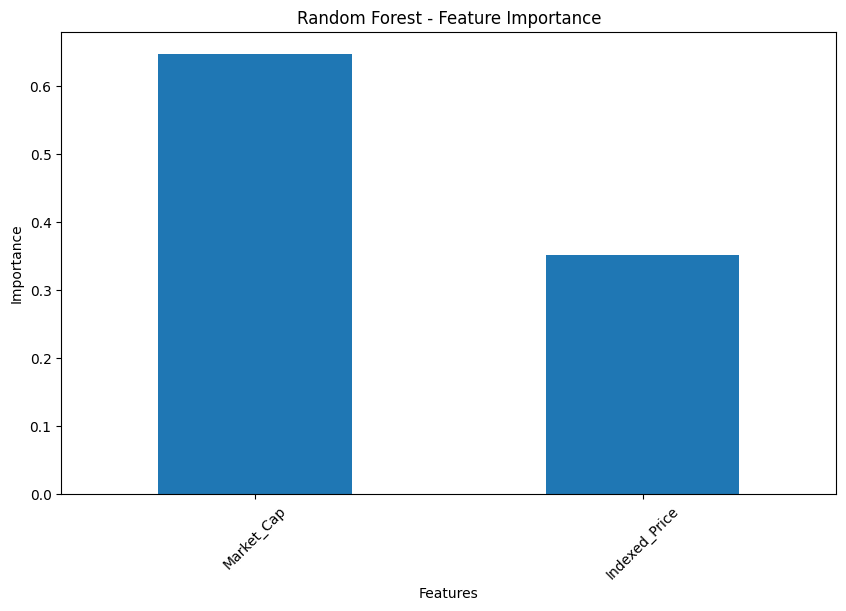

In [146]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

importance.plot(kind='bar')

plt.title('Random Forest - Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45)

plt.show()

In [148]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [151]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [154]:
dt_pred = dt_model.predict(X_test)

In [155]:
dt_accuracy = accuracy_score(y_test, dt_pred)

In [156]:
print(f"Decision Tree Accuracy: {dt_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

         BTC       1.00      1.00      1.00       365
         ETH       1.00      1.00      1.00       365
         SOL       1.00      1.00      1.00       366

    accuracy                           1.00      1096
   macro avg       1.00      1.00      1.00      1096
weighted avg       1.00      1.00      1.00      1096



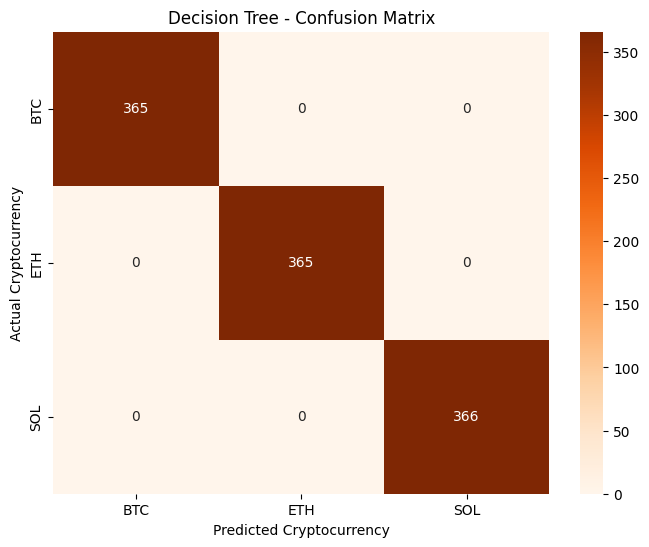

In [157]:
dt_cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Cryptocurrency')
plt.ylabel('Actual Cryptocurrency')

plt.show()

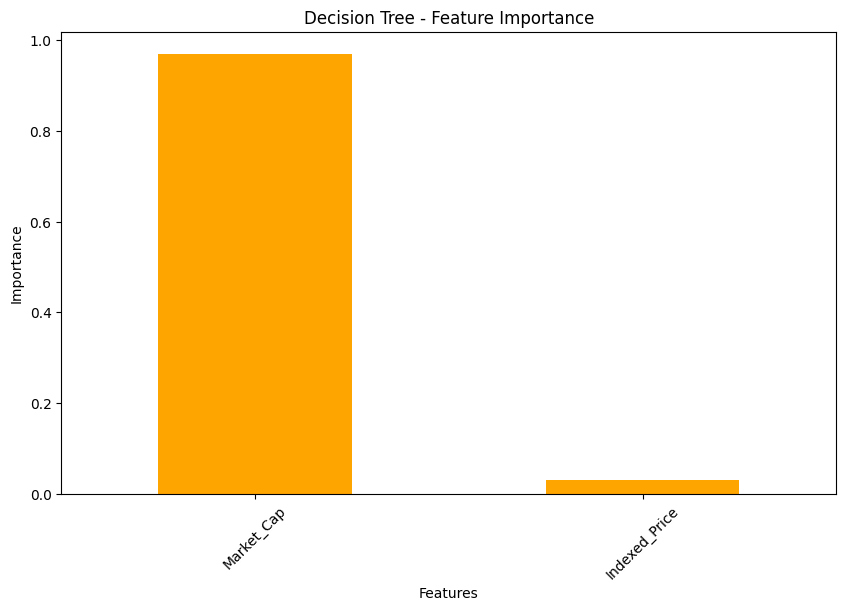

In [158]:
dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

dt_importance.plot(kind='bar', color='orange')

plt.title('Decision Tree - Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45)

plt.show()

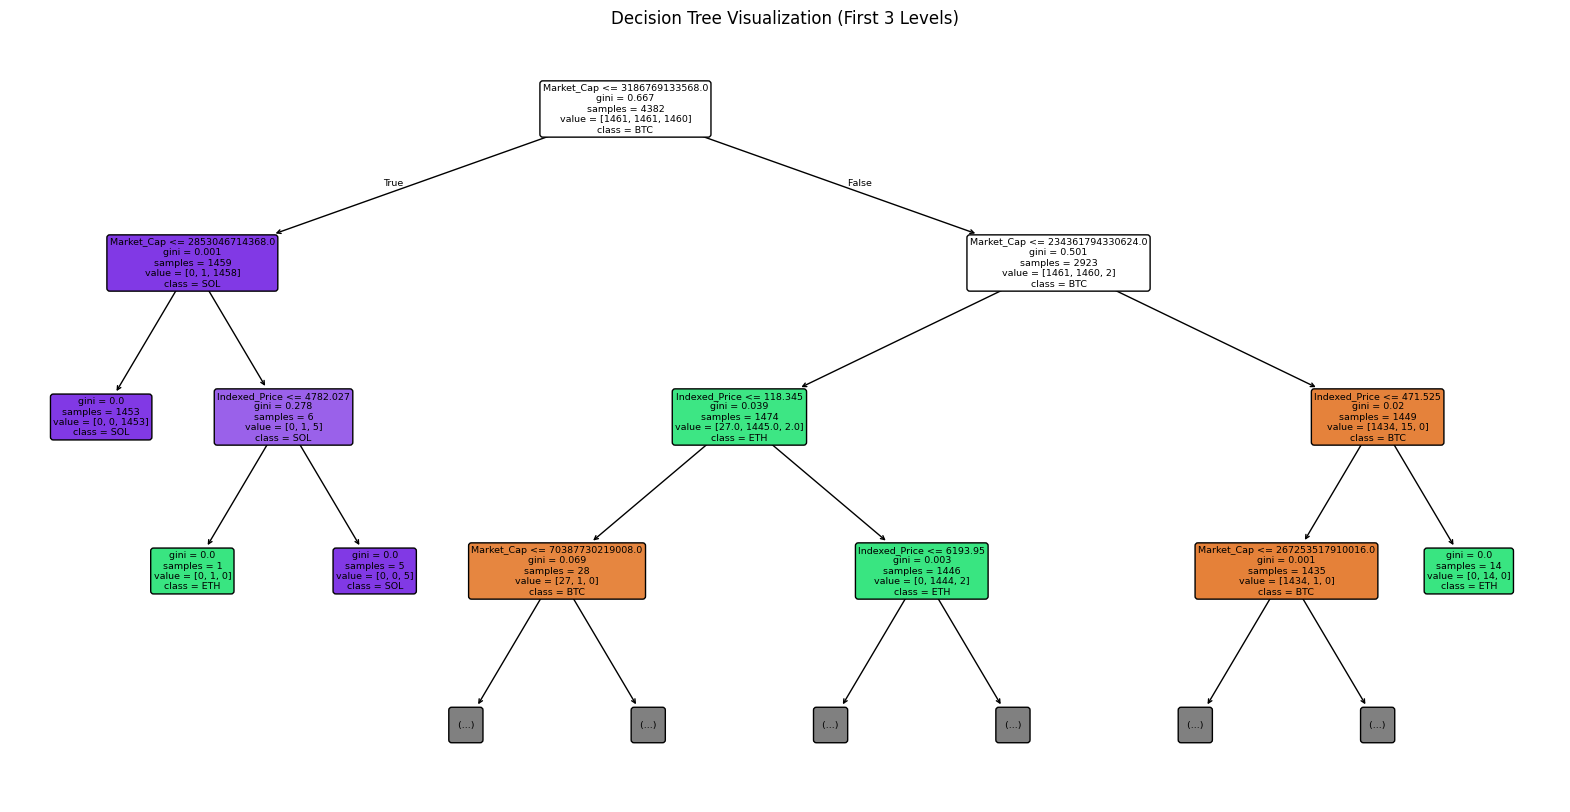

In [159]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title('Decision Tree Visualization (First 3 Levels)')
plt.show()

In [161]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [162]:
# Initialize model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

In [163]:
# Train
svm_model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('svc', SVC())])

In [164]:
# Predict
svm_pred = svm_model.predict(X_test)

In [165]:
# Evaluate
svm_accuracy = accuracy_score(y_test, svm_pred)

In [166]:
print(f"SVM Accuracy: {svm_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 98.18%

Classification Report:
              precision    recall  f1-score   support

         BTC       1.00      0.99      1.00       365
         ETH       0.95      1.00      0.97       365
         SOL       1.00      0.95      0.97       366

    accuracy                           0.98      1096
   macro avg       0.98      0.98      0.98      1096
weighted avg       0.98      0.98      0.98      1096



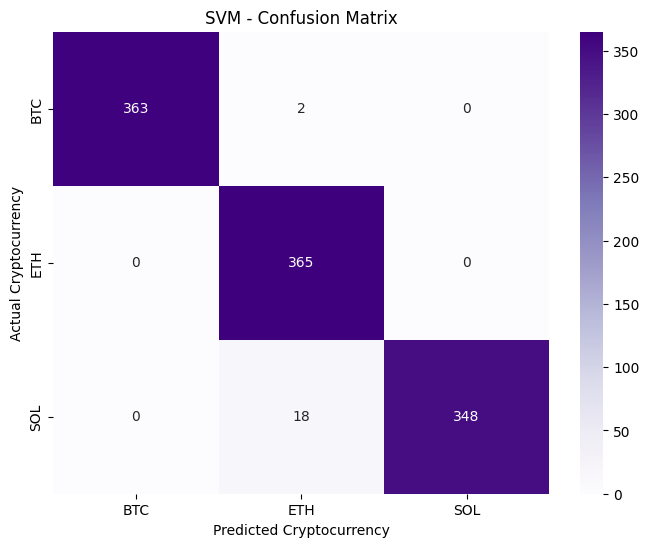

In [167]:
svm_cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title('SVM - Confusion Matrix')
plt.xlabel('Predicted Cryptocurrency')
plt.ylabel('Actual Cryptocurrency')

plt.show()

In [168]:
# Check for duplicate rows
print("Duplicate rows:", crypto_dt.duplicated().sum())

# Check class distribution
print("\nClass distribution:")
print(crypto_dt['Coin'].value_counts())

# Check for missing values
print("\nMissing values:")
print(crypto_dt.isnull().sum())

Duplicate rows: 0

Class distribution:
Coin
BTC    1826
ETH    1826
SOL    1826
Name: count, dtype: int64

Missing values:
Date                      0
Coin                      0
Close                     0
Market_Cap                0
Volume                    0
Daily_Return              3
Indexed_Price             0
MA_30                    87
MA_90                   267
Daily_Return_Decimal      3
Cumulative_Return         3
Running_Peak              3
Drawdown                  3
dtype: int64


In [171]:
# Compare features across cryptocurrencies

features = ['Market_Cap', 'Indexed_Price']

for feature in features:
    print(f"\n{feature} by Cryptocurrency:")
    print(
        crypto_dt.groupby('Coin')[feature]
        .agg(['min', 'max', 'mean', 'std'])
    )


Market_Cap by Cryptocurrency:
               min           max          mean           std
Coin                                                        
BTC   1.308045e+14  2.178225e+16  2.349692e+15  2.427535e+15
ETH   2.881925e+12  3.756027e+14  5.442848e+13  4.941915e+13
SOL   4.738310e+07  8.312690e+12  3.946510e+11  5.889663e+11

Indexed_Price by Cryptocurrency:
             min           max         mean          std
Coin                                                    
BTC    53.745497    424.701723   185.286560   100.305226
ETH   100.000000    661.495518   347.057136   124.806909
SOL    97.676056  14215.950187  5350.598926  3883.834205


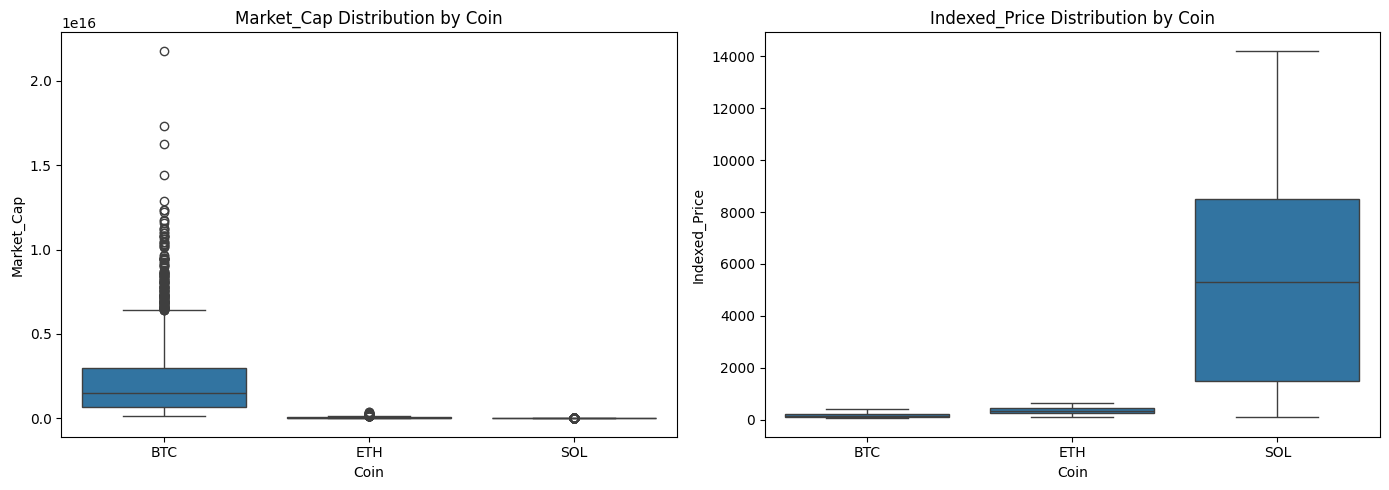

In [172]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=crypto_dt,
        x='Coin',
        y=feature,
        ax=ax
    )
    ax.set_title(f'{feature} Distribution by Coin')

plt.tight_layout()
plt.show()

         Feature  Importance
0     Market_Cap    0.648099
1  Indexed_Price    0.351901


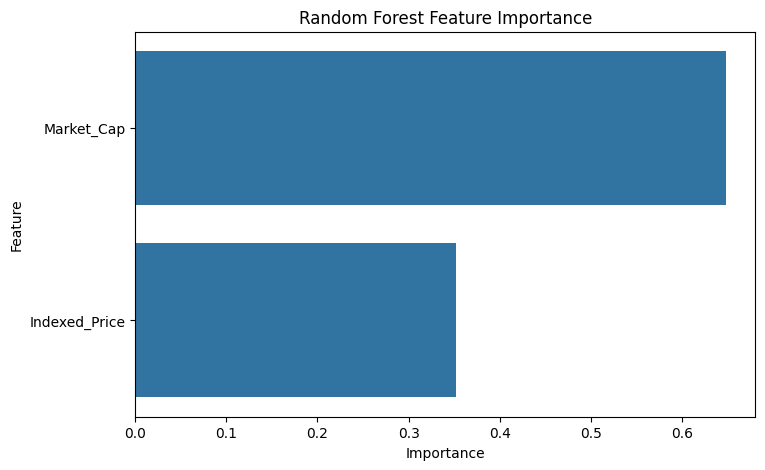

In [173]:
# Random Forest feature importance

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

In [176]:
# Remove Market_Cap
X_new = x.drop(columns=['Market_Cap'])

# Split data
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Random Forest
rf_new = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_new.fit(X_train_new, y_train_new)

# Predict
pred_new = rf_new.predict(X_test_new)

print(
    "Accuracy without Market_Cap:",
    f"{accuracy_score(y_test_new, pred_new):.2%}"
)

Accuracy without Market_Cap: 79.74%


In [177]:
# Remove Indexed_Price
X_market = x.drop(columns=['Indexed_Price'])

# Split data
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_market,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Random Forest
rf_market = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_market.fit(X_train_m, y_train_m)

# Predict
pred_market = rf_market.predict(X_test_m)

# Evaluate
print(
    "Accuracy without Indexed_Price:",
    f"{accuracy_score(y_test_m, pred_market):.2%}"
)

Accuracy without Indexed_Price: 98.36%


In [178]:
# Combine features and target
model_data = X.copy()
model_data['Coin'] = y.values
model_data['Date'] = pd.to_datetime(crypto_dt['Date'])

In [179]:
# Sort chronologically
model_data = model_data.sort_values('Date')

In [180]:
# Remove rows with missing values
model_data = model_data.dropna()


In [181]:
# Separate features and target
X_time = model_data.drop(columns=['Coin', 'Date'])
y_time = model_data['Coin']

In [182]:
# Chronological 80/20 split
split_index = int(len(model_data) * 0.8)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

In [183]:
# Train Random Forest
rf_time = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_time.fit(X_train_time, y_train_time)

RandomForestClassifier(random_state=42)

In [184]:
# Predict
time_pred = rf_time.predict(X_test_time)

In [185]:
# Evaluate
print(
    "Chronological Test Accuracy:",
    f"{accuracy_score(y_test_time, time_pred):.2%}"
)

print(classification_report(y_test_time, time_pred))

Chronological Test Accuracy: 100.00%
              precision    recall  f1-score   support

         BTC       1.00      1.00      1.00       365
         ETH       1.00      1.00      1.00       365
         SOL       1.00      1.00      1.00       366

    accuracy                           1.00      1096
   macro avg       1.00      1.00      1.00      1096
weighted avg       1.00      1.00      1.00      1096



In [186]:
# Check date ranges for training and testing

print("TRAINING PERIOD")

print(
    model_data.iloc[:split_index]
    .groupby('Coin')['Date']
    .agg(['min', 'max', 'count'])
)

print("\nTESTING PERIOD")

print(
    model_data.iloc[split_index:]
    .groupby('Coin')['Date']
    .agg(['min', 'max', 'count'])
)

TRAINING PERIOD
                           min                       max  count
Coin                                                           
BTC  2021-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00   1461
ETH  2021-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00   1461
SOL  2021-01-01 00:00:00+00:00 2024-12-30 00:00:00+00:00   1460

TESTING PERIOD
                           min                       max  count
Coin                                                           
BTC  2025-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00    365
ETH  2025-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00    365
SOL  2024-12-31 00:00:00+00:00 2025-12-31 00:00:00+00:00    366


In [187]:
# Define cutoff date
cutoff_date = pd.Timestamp('2025-01-01', tz='UTC')

# Separate training and testing data
train_data = model_data[
    model_data['Date'] < cutoff_date
]

test_data = model_data[
    model_data['Date'] >= cutoff_date
]

In [188]:
# Separate features and target
X_train_time = train_data.drop(columns=['Coin', 'Date'])
y_train_time = train_data['Coin']

X_test_time = test_data.drop(columns=['Coin', 'Date'])
y_test_time = test_data['Coin']


In [189]:
# Train Random Forest
rf_time = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_time.fit(X_train_time, y_train_time)

RandomForestClassifier(random_state=42)

In [190]:
# Predict
time_pred = rf_time.predict(X_test_time)

In [191]:
# Evaluate
print(
    f"Chronological Accuracy: "
    f"{accuracy_score(y_test_time, time_pred):.2%}"
)

print(classification_report(y_test_time, time_pred))

Chronological Accuracy: 100.00%
              precision    recall  f1-score   support

         BTC       1.00      1.00      1.00       365
         ETH       1.00      1.00      1.00       365
         SOL       1.00      1.00      1.00       365

    accuracy                           1.00      1095
   macro avg       1.00      1.00      1.00      1095
weighted avg       1.00      1.00      1.00      1095



In [192]:
print("Training date range:")
print(train_data.groupby('Coin')['Date'].agg(['min', 'max', 'count']))

print("\nTesting date range:")
print(test_data.groupby('Coin')['Date'].agg(['min', 'max', 'count']))

Training date range:
                           min                       max  count
Coin                                                           
BTC  2021-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00   1461
ETH  2021-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00   1461
SOL  2021-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00   1461

Testing date range:
                           min                       max  count
Coin                                                           
BTC  2025-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00    365
ETH  2025-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00    365
SOL  2025-01-01 00:00:00+00:00 2025-12-31 00:00:00+00:00    365


In [193]:
print(f"Random Forest Accuracy: {accuracy_score(y_test_time, time_pred):.2%}")

Random Forest Accuracy: 100.00%


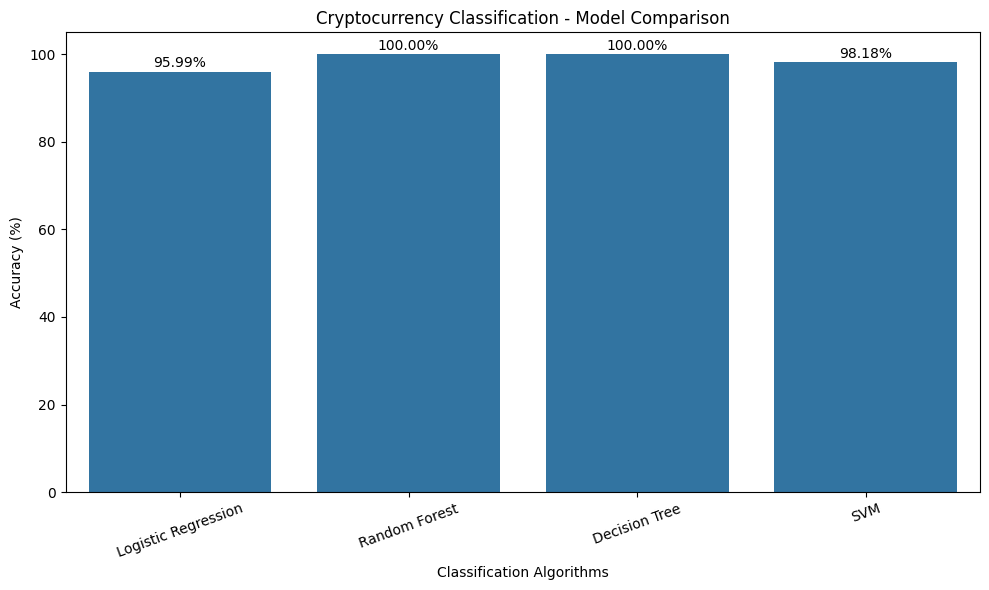

In [194]:
models = [
    'Logistic Regression',
    'Random Forest',
    'Decision Tree',
    'SVM'
]

accuracies = [
    95.99,
    100.00,
    100.00,
    98.18
]

plt.figure(figsize=(10, 6))

sns.barplot(
    x=models,
    y=accuracies
)

plt.title('Cryptocurrency Classification - Model Comparison')
plt.xlabel('Classification Algorithms')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.xticks(rotation=20)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

In [197]:
crypto_dt.head()

,Date,Coin,Close,Market_Cap,Volume,Daily_Return,Indexed_Price,MA_30,MA_90,Daily_Return_Decimal,Cumulative_Return,Running_Peak,Drawdown
0,2021-01-01 00:00:00+00:00,BTC,29374.152344,1.196418e+15,40730301359,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-02 00:00:00+00:00,BTC,32127.267578,2.180331e+15,67865420765,9.372578,109.372578,NaN,NaN,0.093726,1.093726,1.093726,0.000000
2,2021-01-03 00:00:00+00:00,BTC,32782.023438,2.578806e+15,78665235202,2.038007,111.601598,NaN,NaN,0.020380,1.116016,1.116016,0.000000
3,2021-01-04 00:00:00+00:00,BTC,31971.914062,2.594952e+15,81163475344,-2.471200,108.843699,NaN,NaN,-0.024712,1.088437,1.116016,-0.024712
4,2021-01-05 00:00:00+00:00,BTC,33992.429688,2.296098e+15,67547324782,6.319658,115.722249,NaN,NaN,0.063197,1.157222,1.157222,0.000000


In [199]:
# Display dataset information
crypto_dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  5478 non-null   object 
 1   Coin                  5478 non-null   object 
 2   Close                 5478 non-null   float64
 3   Market_Cap            5478 non-null   float64
 4   Volume                5478 non-null   int64  
 5   Daily_Return          5475 non-null   float64
 6   Indexed_Price         5478 non-null   float64
 7   MA_30                 5391 non-null   float64
 8   MA_90                 5211 non-null   float64
 9   Daily_Return_Decimal  5475 non-null   float64
 10  Cumulative_Return     5475 non-null   float64
 11  Running_Peak          5475 non-null   float64
 12  Drawdown              5475 non-null   float64
dtypes: float64(10), int64(1), object(2)
memory usage: 556.5+ KB


In [201]:
# Check for missing values
crypto_dt.isnull().sum()

,0
Date,0
Coin,0
Close,0
Market_Cap,0
Volume,0
Daily_Return,3
Indexed_Price,0
MA_30,87
MA_90,267
Daily_Return_Decimal,3
